# Laboratorium 3: równoległa metoda Jacobiego dla membrany

Notebook uruchamia program `jacobi_mpi.py`, sprawdza jego wyniki i pokazuje pomiary wydajności. Program rozwiązuje równanie $\nabla^2 h = -p/T$ na kwadracie $(0,a)^2$ z warunkiem $h=0$ na brzegu, Algorytmem 1 z `algorytm_opis.pdf`.

MPI nie działa wewnątrz jądra Jupytera, więc każde uruchomienie idzie przez `mpiexec` jako osobne procesy. Pomiary czasu są zapisane w `results/` i powstały w skryptach `benchmark.py` oraz `memory_test.py`. Notebook tylko je wczytuje, więc ponowne uruchomienie nie zmienia tych liczb.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from benchmark import run_solver

RESULTS, FIGURES = Path("results"), Path("figures")
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

# Each grid size keeps the same color and marker on every chart.
SERIES = {128: ("#2a78d6", "o"), 512: ("#eb6834", "s"), 2048: ("#1baf7a", "^")}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 200,
        "font.size": 11,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
    }
)


def finish(fig, name, caption):
    # The caption is part of the image, so it stays in the saved file too.
    fig.text(
        0.5, -0.02, caption, ha="center", va="top", fontsize=10, color=MUTED, wrap=True
    )
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

## 1. Działanie części równoległej

Rozwiązujemy siatkę $n=64$ ($a=p=T=1$) na $P=1,\dots,6$ procesach i zatrzymujemy się przy $\delta<10^{-10}$, sprawdzając warunek co 10 iteracji.

Metoda Jacobiego liczy każdą iterację wyłącznie z poprzedniej, więc wynik powinien być taki sam dla każdego $P$. Błędna wymiana halo od razu zmieniłaby wartości przy granicach bloków, dlatego tabela porównuje każdy przebieg z $P=1$.

In [2]:
N_DEMO = 64
demo = {}
rows = []
for procs in range(1, 7):
    path = RESULTS / f"demo_P{procs}.npz"
    info = run_solver(procs, "--n", N_DEMO, "--eps", 1e-10, "--m", 10, "--output", path)
    demo[procs] = np.load(path)
    rows.append(
        {
            "P": procs,
            "process grid": "x".join(map(str, info["dims"])),
            "iterations": info["k"],
            "delta": info["delta"],
            "max|h_P - h_1|": np.abs(demo[procs]["h"] - demo[1]["h"]).max(),
        }
    )
display(pd.DataFrame(rows).set_index("P"))

,process grid,iterations,delta,max|h_P - h_1|
P,,,,
1,1x1,11460,9.933523e-11,0.0
2,2x1,11460,9.933523e-11,0.0
3,3x1,11460,9.933523e-11,0.0
4,2x2,11460,9.933523e-11,0.0
5,5x1,11460,9.933523e-11,0.0
6,3x2,11460,9.933523e-11,0.0


## 2. Wizualizacja i weryfikacja wyników

Wynik porównujemy z rozwiązaniem analitycznym w postaci szeregu Fouriera, które nie korzysta z żadnego kodu programu:

$$h(x,y)=\frac{16\,p\,a^2}{T\pi^4}\sum_{k,l\ \text{nieparzyste}}\frac{\sin(k\pi x/a)\,\sin(l\pi y/a)}{k\,l\,(k^2+l^2)}$$

In [3]:
def analytic(n, a=1.0, p=1.0, T=1.0, terms=200):
    # Fourier series on the (n+1) x (n+1) grid nodes.
    k = 2 * np.arange(terms) + 1
    s = np.sin(np.pi * np.outer(np.arange(n + 1) / n, k))
    coef = 16 * p * a**2 / (T * np.pi**4) / (np.outer(k, k) * np.add.outer(k**2, k**2))
    return s @ coef @ s.T


result = demo[4]
h, owner = result["h"], result["owner"]
exact = analytic(N_DEMO)
centre = N_DEMO // 2

# Check equation (5) on inner nodes. This does not depend on the stop rule.
residual = (
    h[2:, 1:-1] + h[:-2, 1:-1] + h[1:-1, 2:] + h[1:-1, :-2] - 4 * h[1:-1, 1:-1]
) * N_DEMO**2 + 1

print(
    f"h(a/2, a/2): computed {h[centre, centre]:.6f}, analytic {exact[centre, centre]:.6f}"
)
print(f"max error against the series: {np.abs(h - exact).max():.2e}")
print(f"max residual of equation (5): {np.abs(residual).max():.2e}")
print(
    f"max |h| on the edge: {max(np.abs(h[[0, -1], :]).max(), np.abs(h[:, [0, -1]]).max()):.1f}"
)
print(f"asymmetry, max|h - h^T|: {np.abs(h - h.T).max():.2e}")

h(a/2, a/2): computed 0.073657, analytic 0.073671
max error against the series: 1.42e-05
max residual of equation (5): 1.63e-06
max |h| on the edge: 0.0
asymmetry, max|h - h^T|: 4.16e-17


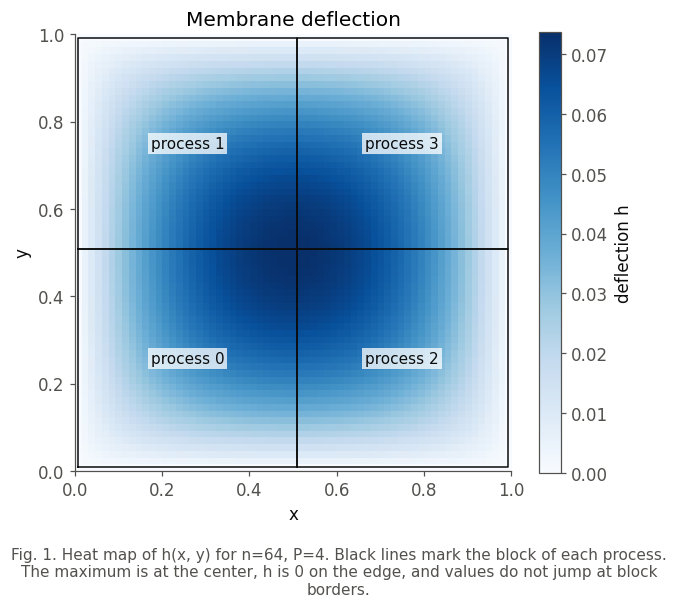

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 5.2))
image = ax.imshow(
    h.T, origin="lower", extent=[0, 1, 0, 1], cmap="Blues", interpolation="nearest"
)
ax.grid(False)
fig.colorbar(image, ax=ax, label="deflection h")
# Draw each block and its process number.
x = np.arange(N_DEMO + 1) / N_DEMO
half_cell = 0.5 / N_DEMO
for rank in np.unique(owner[owner >= 0]):
    i, j = np.nonzero(owner == rank)
    xs, ys = x[[i.min(), i.max()]], x[[j.min(), j.max()]]
    ax.plot(
        [
            xs[0] - half_cell,
            xs[1] + half_cell,
            xs[1] + half_cell,
            xs[0] - half_cell,
            xs[0] - half_cell,
        ],
        [
            ys[0] - half_cell,
            ys[0] - half_cell,
            ys[1] + half_cell,
            ys[1] + half_cell,
            ys[0] - half_cell,
        ],
        color=INK,
        lw=1,
    )
    ax.text(
        xs.mean(),
        ys.mean(),
        f"process {rank}",
        ha="center",
        va="center",
        color=INK,
        fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=2),
    )
ax.set(xlabel="x", ylabel="y", title="Membrane deflection")
finish(
    fig,
    "fig1_heatmap",
    f"Fig. 1. Heat map of h(x, y) for n={N_DEMO}, P=4. Black lines mark the block of each process.\nThe maximum is at the center, h is 0 on the edge, and values do not jump at block borders.",
)

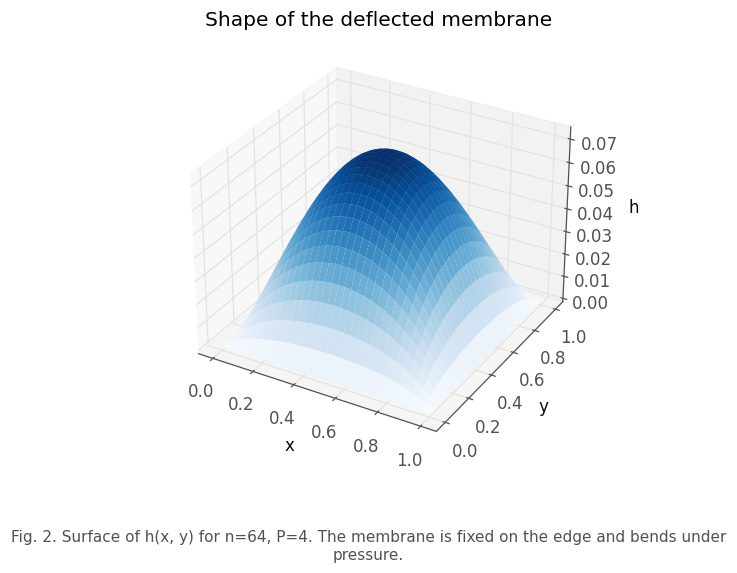

In [5]:
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
X, Y = np.meshgrid(x, x, indexing="ij")
ax.plot_surface(X, Y, h, cmap="Blues", linewidth=0, antialiased=True)
ax.set(xlabel="x", ylabel="y", zlabel="h", title="Shape of the deflected membrane")
ax.zaxis.labelpad = 6
finish(
    fig,
    "fig2_surface",
    f"Fig. 2. Surface of h(x, y) for n={N_DEMO}, P=4. The membrane is fixed on the edge and bends under pressure.",
)

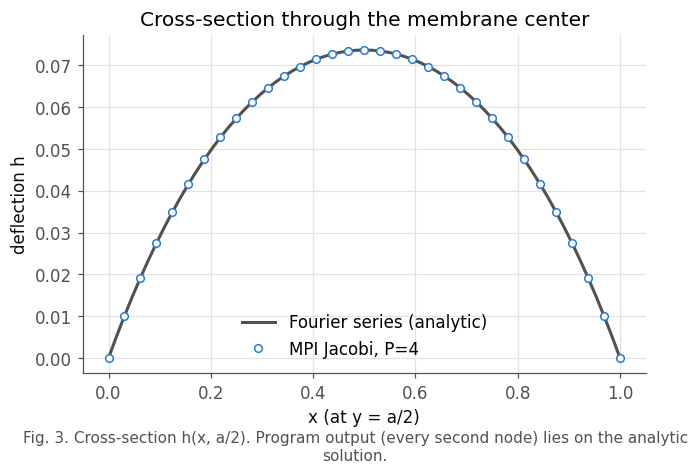

In [6]:
fig, ax = plt.subplots(figsize=(6.6, 4))
ax.plot(x, exact[:, centre], color=MUTED, lw=2, label="Fourier series (analytic)")
ax.plot(
    x[::2],
    h[::2, centre],
    ls="none",
    marker="o",
    ms=5,
    mfc="white",
    color="#2a78d6",
    label="MPI Jacobi, P=4",
)
ax.set(
    xlabel="x (at y = a/2)",
    ylabel="deflection h",
    title="Cross-section through the membrane center",
)
ax.legend(loc="lower center")
finish(
    fig,
    "fig3_cross_section",
    "Fig. 3. Cross-section h(x, a/2). Program output (every second node) lies on the analytic solution.",
)

Schemat (5) ma błąd $O(d^2)$, więc dwa razy gęstsza siatka powinna dawać około cztery razy mniejszy błąd. Sprawdzamy to na siatkach od $n=16$ do $n=128$.

,d,max error,order
n,,,
16,0.062500,0.000226,NaN
32,0.031250,0.000057,1.994406
64,0.015625,0.000014,1.997974
128,0.007812,0.000004,1.986717


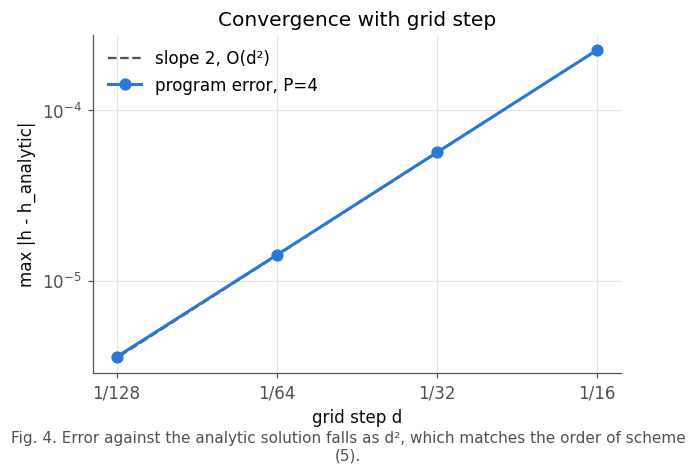

In [7]:
ns = [16, 32, 64, 128]
errors = []
for n in ns:
    path = RESULTS / f"conv_n{n}.npz"
    run_solver(4, "--n", n, "--eps", 1e-11, "--m", 100, "--output", path)
    errors.append(np.abs(np.load(path)["h"] - analytic(n)).max())
errors = np.array(errors)
d = 1 / np.array(ns)
order = np.log2(errors[:-1] / errors[1:])
display(
    pd.DataFrame(
        {"n": ns, "d": d, "max error": errors, "order": [np.nan, *order]}
    ).set_index("n")
)

fig, ax = plt.subplots(figsize=(6.2, 4))
ax.loglog(
    d, errors[0] * (d / d[0]) ** 2, color=MUTED, ls="--", lw=1.5, label="slope 2, O(d²)"
)
ax.loglog(
    d, errors, color="#2a78d6", marker="o", ms=7, lw=2, label="program error, P=4"
)
ax.set(
    xlabel="grid step d",
    ylabel="max |h - h_analytic|",
    title="Convergence with grid step",
)
ax.set_xticks(d, [f"1/{n}" for n in ns])
ax.minorticks_off()
ax.legend()
finish(
    fig,
    "fig4_convergence",
    "Fig. 4. Error against the analytic solution falls as d², which matches the order of scheme (5).",
)

## 3. Analiza wydajności

Mierzymy ten sam program dla $P=1,\dots,6$ na procesorze i5-9400F (6 rdzeni bez hyper-threadingu). $T(1)$ to przebieg na jednym procesie. Dla danego $n$ liczba iteracji jest stała: 20000 dla $n=128$, 3000 dla $n=512$ i 200 dla $n=2048$. Czas biegnie od bariery po inicjalizacji do końca pętli i liczymy go na najwolniejszym procesie.

Każdy punkt to mediana z 5 pomiarów, a słupki pokazują kwartyle 25–75%. Mediana jest potrzebna, bo w czasie pomiarów na komputerze działały inne programy i pojedyncze przebiegi trwały kilka razy dłużej (kolumna `T_max`).

In [8]:
raw = pd.read_csv(RESULTS / "benchmark_local.csv")

stats = (
    raw.groupby(["n", "P"])
    .agg(
        T=("time", "median"),
        T_q1=("time", lambda t: t.quantile(0.25)),
        T_q3=("time", lambda t: t.quantile(0.75)),
        T_max=("time", "max"),
        comm=("comm_time", "median"),
        dims=("dims", "first"),
    )
    .reset_index()
)
T1 = stats[stats.P == 1].set_index("n")["T"]


def speedup(t, n):
    return T1[n] / t


def efficiency(t, n, procs):
    return speedup(t, n) / procs


def karp_flatt(t, n, procs):
    return (1 / speedup(t, n) - 1 / procs) / (1 - 1 / procs)


stats["S"] = stats.n.map(T1) / stats["T"]
stats["E"] = stats.S / stats.P
stats["f"] = (1 / stats.S - 1 / stats.P) / (1 - 1 / stats.P)  # NaN for P=1
stats["comm [%]"] = 100 * stats.comm / stats["T"]
pd.set_option("display.precision", 3)
display(
    stats[
        ["n", "P", "dims", "T", "T_q1", "T_q3", "T_max", "S", "E", "f", "comm [%]"]
    ].set_index(["n", "P"])
)

dims      T   T_q1   T_q3   T_max      S      E      f  comm [%]
n    P                                                                 
128  1  1x1  2.681  2.673  2.791   2.800  1.000  1.000    NaN     7.860
     2  2x1  1.909  1.890  1.915  11.786  1.405  0.702  0.424    20.769
     3  3x1  1.598  1.542  1.718   2.561  1.678  0.559  0.394    28.817
     4  2x2  1.663  1.639  1.685  11.732  1.612  0.403  0.494    40.937
     5  5x1  1.463  1.432  1.630  15.095  1.833  0.367  0.432    41.460
     6  3x2  1.757  1.672  2.678  17.866  1.526  0.254  0.586    53.473
512  1  1x1  5.215  4.927  5.245   6.578  1.000  1.000    NaN     1.107
     2  2x1  2.818  2.556  3.036   3.285  1.850  0.925  0.081     4.262
     3  3x1  2.023  1.900  2.029   2.146  2.578  0.859  0.082     6.515
     4  2x2  1.760  1.585  1.799   1.899  2.963  0.741  0.117    13.606
     5  5x1  1.630  1.402  1.695   1.842  3.199  0.640  0.141    22.603
     6  3x2  1.597  1.365  1.761   3.120  3.265  0.544  0.168    26.122
2048 1  1x1  8.291  8.011  8.870   8.885  1.000  1.000    NaN     0.213
     2  2x1  5.590  5.386  5.965  14.796  1.483  0.742  0.348     0.636
     3  3x1  5.343  5.091  5.660   8.904  1.552  0.517  0.467     1.464
     4  2x2  5.344  5.129  5.752  10.521  1.551  0.388  0.526     4.061
     5  5x1  5.050  4.842  5.307   6.067  1.642  0.328  0.511     7.293
     6  3x2  5.451  5.107  5.598   5.789  1.521  0.254  0.589    20.272

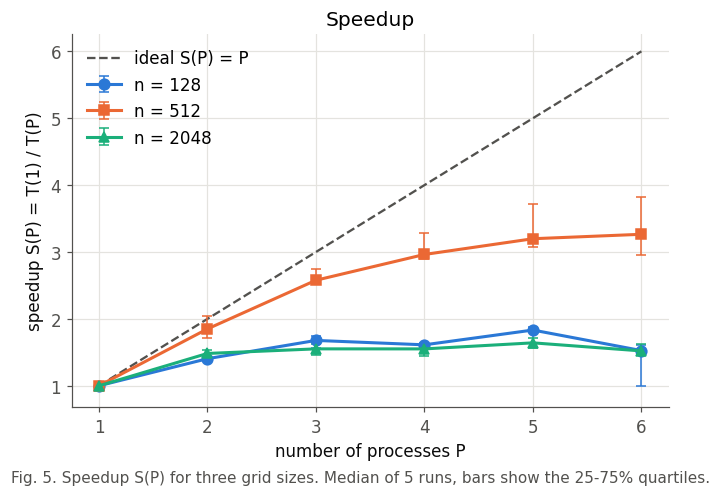

In [9]:
def metric_plot(
    metric,
    ylabel,
    title,
    name,
    caption,
    ideal=None,
    ideal_label=None,
    start_p=1,
    legend_loc="best",
):
    fig, ax = plt.subplots(figsize=(7, 4.4))
    if ideal is not None:
        ps = np.arange(start_p, 7)
        ax.plot(ps, ideal(ps), color=MUTED, ls="--", lw=1.5, label=ideal_label)
    for n, (color, marker) in SERIES.items():
        g = stats[(stats.n == n) & (stats.P >= start_p)]
        y = metric(g["T"], n, g.P)
        low, high = metric(g.T_q3, n, g.P), metric(g.T_q1, n, g.P)
        lo, hi = np.minimum(low, high), np.maximum(low, high)
        ax.errorbar(
            g.P,
            y,
            yerr=[np.maximum(y - lo, 0), np.maximum(hi - y, 0)],
            color=color,
            marker=marker,
            ms=7,
            lw=2,
            capsize=3,
            elinewidth=1,
            label=f"n = {n}",
        )
    ax.set(
        xlabel="number of processes P",
        ylabel=ylabel,
        title=title,
        xticks=range(start_p, 7),
    )
    ax.legend(loc=legend_loc)
    finish(fig, name, caption)


NOTE = "Median of 5 runs, bars show the 25-75% quartiles."
metric_plot(
    lambda t, n, p: speedup(t, n),
    "speedup S(P) = T(1) / T(P)",
    "Speedup",
    "fig5_speedup",
    f"Fig. 5. Speedup S(P) for three grid sizes. {NOTE}",
    ideal=lambda p: p,
    ideal_label="ideal S(P) = P",
    legend_loc="upper left",
)

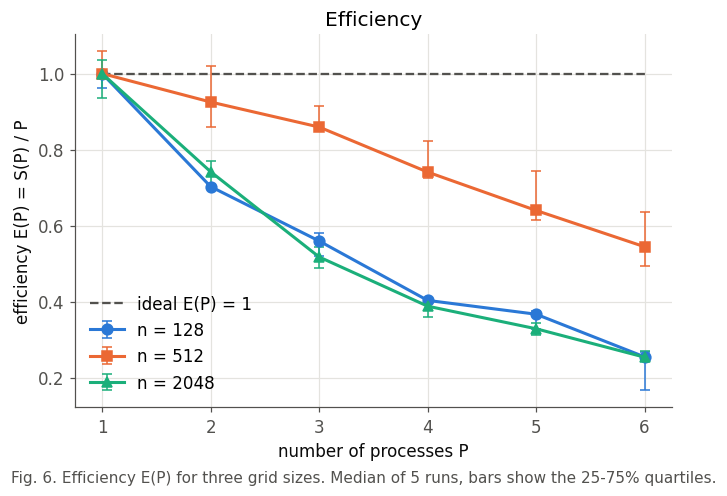

In [10]:
metric_plot(
    efficiency,
    "efficiency E(P) = S(P) / P",
    "Efficiency",
    "fig6_efficiency",
    f"Fig. 6. Efficiency E(P) for three grid sizes. {NOTE}",
    ideal=lambda p: np.ones_like(p, dtype=float),
    ideal_label="ideal E(P) = 1",
)

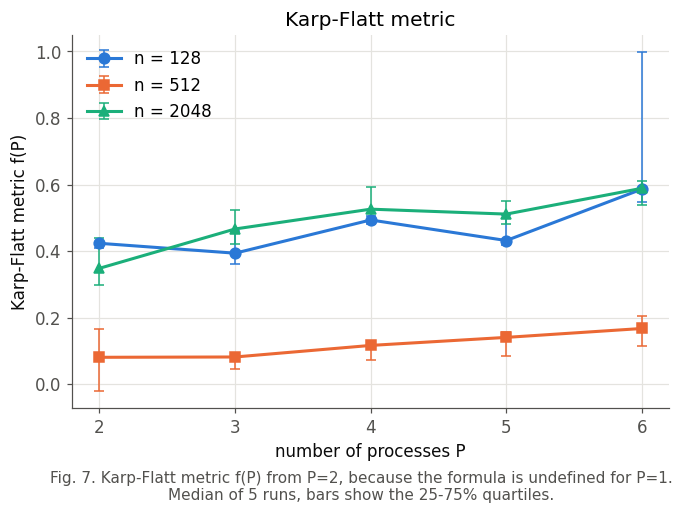

In [11]:
metric_plot(
    karp_flatt,
    "Karp-Flatt metric f(P)",
    "Karp-Flatt metric",
    "fig7_karp_flatt",
    f"Fig. 7. Karp-Flatt metric f(P) from P=2, because the formula is undefined for P=1.\n{NOTE}",
    start_p=2,
)

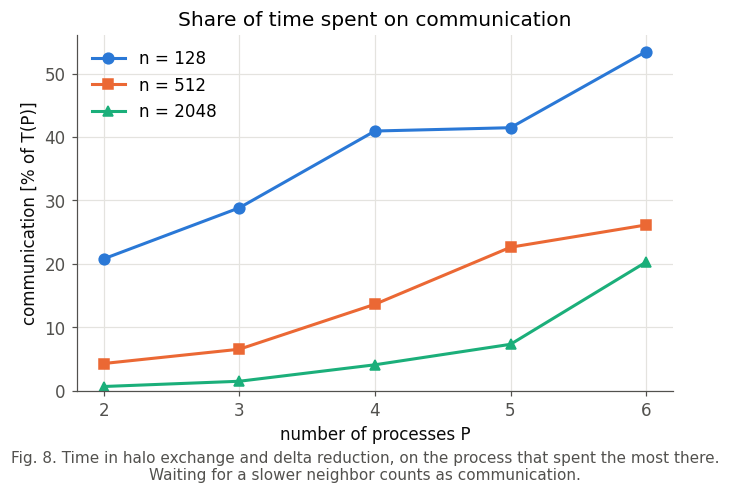

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for n, (color, marker) in SERIES.items():
    g = stats[(stats.n == n) & (stats.P > 1)]
    ax.plot(
        g.P, g["comm [%]"], color=color, marker=marker, ms=7, lw=2, label=f"n = {n}"
    )
ax.set(
    xlabel="number of processes P",
    ylabel="communication [% of T(P)]",
    title="Share of time spent on communication",
    xticks=range(2, 7),
    ylim=(0, None),
)
ax.legend()
finish(
    fig,
    "fig8_communication",
    "Fig. 8. Time in halo exchange and delta reduction, on the process that spent the most there.\nWaiting for a slower neighbor counts as communication.",
)

### Czy ograniczeniem jest pamięć?

Przy $n=2048$ i $P=6$ komunikacja zajmuje 20% czasu, a przyspieszenie to tylko 1,52. Żeby sprawdzić, skąd reszta strat, `memory_test.py` uruchamia kilka niezależnych kopii programu, po jednym procesie każda. Kopie nie komunikują się ze sobą i każda wykonuje stałą pracę, więc bez wspólnego sprzętu ich czas by się nie zmieniał. Siatki $n=209$ i $n=836$ mają tyle węzłów, ile jeden blok przy $P=6$ dla $n=512$ i $n=2048$.

In [13]:
copies = pd.read_csv(RESULTS / "memory_test.csv")
copies_median = copies.groupby(["block", "copies"]).time.median().unstack(0)
slowdown = (copies_median / copies_median.loc[1]).rename(
    columns={"small": "small block (n=209)", "large": "large block (n=836)"}
)
print("Slowdown of one copy compared with running alone (median of 9 repeats):")
display(slowdown)

# The same effect in the main measurements: compute time per node, without communication.
nodes = (stats.n - 1) ** 2 / stats.P
iterations = stats.n.map(raw.groupby("n").k.first())
stats["ns per node"] = (stats["T"] - stats.comm) / (iterations * nodes) * 1e9
print("Compute time per node [ns]:")
display(stats.pivot(index="P", columns="n", values="ns per node"))

Slowdown of one copy compared with running alone (median of 9 repeats):


block,large block (n=836),small block (n=209)
copies,,
1,1.000,1.000
2,1.475,1.018
4,2.734,1.068
6,4.155,1.347


Compute time per node [ns]:


n,128,512,2048
P,,,
1,7.659,6.583,9.872
2,9.375,6.889,13.255
3,10.578,7.243,18.845
4,12.181,7.764,24.473
5,13.272,8.054,27.931
6,15.206,9.038,31.113


## 4. Wnioski

Najlepiej skaluje się $n=512$: $S(6)=3{,}27$ i $E(6)=0{,}54$. Komunikacja zajmuje tam 26% czasu przy $P=6$, a obliczenia na jeden węzeł zwalniają tylko z 6,6 ns do 9,0 ns.

Przy $n=2048$ przyspieszenie zatrzymuje się na około 1,5, bo obliczenia na węzeł zwalniają z 9,9 ns do 31,1 ns. Sześć procesów działa wtedy tak, jakby każdy miał trzecią część mocy rdzenia. Test z kopiami pokazuje to samo bez MPI: sześć kopii dużego bloku działa 4,15 raza wolniej, a małego 1,35 raza wolniej. Rdzenie dzielą pamięć podręczną L3 i RAM, a duże bloki nie mieszczą się w L3.

Przy $n=128$ każdy proces ma mało węzłów, więc rosną koszty stałe. Przy $P=6$ komunikacja zajmuje 53% czasu. Czas obliczeń na iterację dobrze opisuje wzór $24\,\mu s + 6{,}1\,\text{ns} \cdot$ liczba węzłów, co wskazuje na stały narzut Pythona i NumPy. To oszacowanie z dopasowania, bez osobnego pomiaru.

Metryka $f(P)$ ogólnie rośnie z $P$ (dla $n=128$ nierówno), więc opisuje narzuty zależne od liczby procesów. Stała część sekwencyjna dałaby płaską krzywą.